# 05 — Stage E: testing H1, H2 and H3

Three hypotheses from the proposal, restated as measurements:

| | claim | measurement |
|---|---|---|
| **H1** | with missing inputs the wind-following model degrades least: GNN(wind) < GNN(fixed) < non-graph/trivial | MAE vs. share of silent turbines, at 10 min / 1 h / 6 h, identical masks and windows |
| **H2** | the benefit is largest for turbines with several upwind neighbours, ≈0 for front-row turbines | degradation grouped by the number of upwind neighbours **at the current wind** |
| **H3** | losing an upwind turbine hurts its downwind neighbour more than the reverse | paired test on directed pairs: hide `i`, score `j` vs. hide `j`, score `i` |

**Design rules that make the comparison meaningful**

* **One architecture, several graphs.** Every rung shares the encoder, decoder, optimiser,
  windows, masks and seeds; only the graph (or its absence) changes. Otherwise a difference
  cannot be attributed to the graph.
* **The reversed orientation is a baseline.** Stage B could not decide which end of the farm axis
  is downstream, so `alpha + 180` is a legitimate competitor, not a sanity check.
* **Direction-blind controls.** The soft cone (`cone = 180`, direction only as an edge feature)
  and `k = 5` kNN are the "any neighbour will do" contenders; a directional benefit has to beat
  them.
* **Every comparison is paired** on the same windows and masks, and repeated over≥3 seeds in
  `quick`/`full` mode.
* **Cost.** This notebook trains several models; the checkpoints from notebook 04 are reused when
  present, and every run is cached under `results/checkpoints/`, so re-running is cheap.

## 0. Setup

In [9]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd()
while not (ROOT / "src" / "windgnn").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from windgnn import config as C, data as D, graphs as G, tensors as T
from windgnn import models as M, training as TR, evaluation as E, explain as X, viz as V
from windgnn.tensors import WindowSpec, GraphProvider, ForecastWindows, RandomTurbineMasker

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)

print("torch", torch.__version__, "| HIP", torch.version.hip, "| CUDA", torch.version.cuda)
print("device:", TR.resolve_device(), "| visible GPUs:", torch.cuda.device_count())
for _i in range(torch.cuda.device_count()):
    print(f"  gpu[{_i}]: {torch.cuda.get_device_name(_i)}")

torch 2.13.0+rocm7.1 | HIP 7.1.52802 | CUDA None
device: cuda | visible GPUs: 2
  gpu[0]: AMD Radeon Graphics
  gpu[1]: AMD Ryzen 5 7600 6-Core Processor


In [10]:
#: "smoke" runs in well under a minute on a slice of the data (pipeline check);
#: "quick" is the default for a first real answer; "full" is the report-quality run.
RUN = os.environ.get("WINDGNN_RUN", "full")
PRESETS = {
    "smoke": dict(train_stride=1997, val_stride=499, samples_per_epoch=32,  epochs=1,  test_stride=1499,
                  seeds=(0,), n_explain=3),
    "quick": dict(train_stride=3,   val_stride=3,   samples_per_epoch=600, epochs=30, test_stride=11,
                  seeds=(0, 1, 2), n_explain=24),
    "full":  dict(train_stride=1,   val_stride=1,   samples_per_epoch=3000, epochs=120, test_stride=1,
                  seeds=(0, 1, 2, 3, 4), n_explain=150),
}
P = PRESETS[RUN]
print(f"RUN = {RUN!r} -> {P}")

RUN = 'full' -> {'train_stride': 1, 'val_stride': 1, 'samples_per_epoch': 3000, 'epochs': 120, 'test_stride': 1, 'seeds': (0, 1, 2, 3, 4), 'n_explain': 150}


In [11]:
SPEC = WindowSpec(input_len=12, horizons=(1, 6, 36))   # 2 h of history; 10 min / 1 h / 6 h ahead
fd = T.build_feature_data()
meta = T.load_graph_meta()
ALPHA, RADIUS = float(meta["alpha_deg"]), float(meta["radius_primary_m"])
print(f"{fd.x.shape[0]:,} timestamps x {fd.n_turbines} turbines x {len(fd.names)} features")
print(f"graph configuration from Stage B: alpha = {ALPHA:.0f} deg, R = {RADIUS:.0f} m, "
      f"cone = {meta['cone_primary_deg']:.0f} deg (primary)")
print("features:", ", ".join(fd.names))

35,280 timestamps x 134 turbines x 15 features
graph configuration from Stage B: alpha = 275 deg, R = 1500 m, cone = 45 deg (primary)
features: patv, wspd, wdir_sin, wdir_cos, etmp, itmp, ndir_sin, ndir_cos, pab1, prtv, farm_sin, farm_cos, tod_sin, tod_cos, observed


In [12]:
train_t, train_h = T.sample_indices(fd, SPEC, "train", stride=P["train_stride"])
val_t, val_h = T.sample_indices(fd, SPEC, "val", stride=P["val_stride"])
test_t, test_h = T.sample_indices(fd, SPEC, "test", stride=P["test_stride"])
print(f"windows: train {len(train_t):,} val {len(val_t):,} test {len(test_t):,}")

train_ds = ForecastWindows(fd, train_t, train_h, SPEC, masker=RandomTurbineMasker(0.5, seed=0))
val_ds = ForecastWindows(fd, val_t, val_h, SPEC, masker=RandomTurbineMasker(0.5, seed=1))

windows: train 73,796 val 10,724 test 21,092


## 1. The model zoo — one body, six graphs

| name | graph | why it is in the comparison |
|---|---|---|
| `MLP (no graph)` | none | the non-graph baseline the proposal asks for |
| `GCN (static kNN)` | kNN, distance weights | the "standard graph model on a fixed distance graph" |
| `GAT v1 (soft cone)` | soft cone, static attention | isolates *query-dependent* attention (GATv2) from attention per se |
| `GATv2 (kNN)` | kNN + edge features | graph topology fixed, attention over distance only |
| `GATv2 (soft cone)` | all pairs within `R` | **the model**: direction and angle as edge features |
| `GATv2 (hard cone 45)` | cone 45° | the proposal's literal directed-upwind graph |
| `GATv2 (reversed 45)` | cone 45°, reversed | the orientation control |

Every entry is trained with the same hyperparameters and the same random-hiding augmentation.

In [13]:
def build_zoo():
    alpha, radius = ALPHA, RADIUS
    mk = lambda **kw: GraphProvider(fd.loc, fd.farm_dir, fd.t_index, alpha, radius,
                                    **kw)
    return {
        "MLP (no graph)":         dict(graph=mk(kind="none"),                       model=dict(graph="none")),
        "GCN (static kNN)":       dict(graph=mk(kind="knn", k=5),                   model=dict(graph="gcn", edge_dim=None)),
        "GAT v1 (soft cone)":     dict(graph=mk(cone_deg=180.0),                        model=dict(graph="gat")),
        "GATv2 (kNN)":            dict(graph=mk(kind="knn", k=5),                   model=dict(graph="gatv2")),
        "GATv2 (soft cone)":      dict(graph=mk(cone_deg=180.0),                        model=dict(graph="gatv2")),
        "GATv2 (hard cone 45)":   dict(graph=mk(cone_deg=45.0),                         model=dict(graph="gatv2")),
        "GATv2 (reversed 45)":    dict(graph=mk(cone_deg=45.0, reverse=True),           model=dict(graph="gatv2")),
    }

ZOO = build_zoo()
if RUN == "smoke":
    keep = ["MLP (no graph)", "GATv2 (soft cone)"]
    ZOO = {k: v for k, v in ZOO.items() if k in keep}
print(f"{len(ZOO)} models x {len(P['seeds'])} seed(s) = {len(ZOO)*len(P['seeds'])} runs")
for k, v in ZOO.items():
    print(f"  {k:24s} {v['model']}")

7 models x 5 seed(s) = 35 runs
  MLP (no graph)           {'graph': 'none'}
  GCN (static kNN)         {'graph': 'gcn', 'edge_dim': None}
  GAT v1 (soft cone)       {'graph': 'gat'}
  GATv2 (kNN)              {'graph': 'gatv2'}
  GATv2 (soft cone)        {'graph': 'gatv2'}
  GATv2 (hard cone 45)     {'graph': 'gatv2'}
  GATv2 (reversed 45)      {'graph': 'gatv2'}


In [14]:
def slug(name):
    import re
    return re.sub(r"_+", "_", "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in name)).strip("_")

def get_model(name, seed):
    """Train (or load from cache) one model of the zoo and return it.

    A cached checkpoint is only reused when it was produced by the **same run mode**: a `quick`
    model silently standing in for a `full` run would invalidate the whole comparison, so the
    ``run`` field of the checkpoint metadata is checked before the weights are touched.
    """
    entry = ZOO[name]
    ckpt_name = f"stage_e_{slug(name)}"

    def build():
        return M.build_model(entry["model"], n_features=len(fd.names),
                             n_horizons=len(SPEC.horizons),
                             patv_feature=fd.feature_index("patv"))

    ckpt = TR.checkpoint_path(ckpt_name, seed)
    if ckpt.exists():
        meta = torch.load(ckpt, map_location="cpu", weights_only=False).get("meta", {})
        if meta.get("run") == RUN:
            torch.manual_seed(seed)
            model = build()
            TR.load_checkpoint(model, ckpt_name, seed)
            print(f"  {name} seed {seed}: loaded {ckpt.name} (run={RUN})")
            return model, True
        print(f"  {name} seed {seed}: {ckpt.name} was run={meta.get('run')!r} "
              f"-> retraining for run={RUN!r}")

    torch.manual_seed(seed)
    model = build()
    cfg = TR.TrainConfig(epochs=P["epochs"], samples_per_epoch=P["samples_per_epoch"],
                         seed=seed, verbose=False)
    trainer = TR.fit_model(model, train_ds, val_ds, entry["graph"], cfg, fd)
    TR.save_checkpoint(trainer, ckpt_name, seed,
                       meta={"zoo": name, "run": RUN, "best_val": trainer.best_val})
    print(f"  {name} seed {seed}: trained ({RUN}), val MAE {trainer.best_val:.1f} kW")
    return trainer.model, False

## 2. The scenario suite

All models are scored on the **same windows** with the **same silent turbines**, using the same
mask matrices. `random x%` hides a uniformly random subset per window; `block 10%` hides a
contiguous id range (ids run along the columns, so this is a spatially coherent outage); `one at
a time` hides exactly one turbine per window, cycling through all 134.

In [15]:
SHARES = (0.05, 0.10, 0.20, 0.30, 0.40, 0.50)
columns = G.detect_columns(fd.loc)
scenario_masks = {"complete data": np.zeros((len(test_t), fd.n_turbines), dtype=bool)}
for share in SHARES:
    scenario_masks[f"random {int(share*100)}%"] = T.outage_masks(
        len(test_t), fd.n_turbines, share, "random", seed=int(share * 1000))
scenario_masks["block 10%"] = T.outage_masks(len(test_t), fd.n_turbines, 0.10, "block", seed=7)
scenario_masks["whole columns"] = T.outage_masks(len(test_t), fd.n_turbines, 0.10, "column",
                                                 columns=columns)
print({k: round(v.mean(), 3) for k, v in scenario_masks.items()})

def evaluate_suite(model, graph):
    out = {}
    for name, mask in scenario_masks.items():
        ds = ForecastWindows(fd, test_t, test_h, SPEC, fixed_hidden=mask)
        out[name] = TR.predict(model, ds, graph, batch_size=64)
    return out

{'complete data': np.float64(0.0), 'random 5%': np.float64(0.052), 'random 10%': np.float64(0.097), 'random 20%': np.float64(0.201), 'random 30%': np.float64(0.299), 'random 40%': np.float64(0.403), 'random 50%': np.float64(0.5), 'block 10%': np.float64(0.097), 'whole columns': np.float64(0.164)}


## 3. Run everything

Each model is trained (or loaded), scored on the full suite, and — importantly — **also scored
per horizon**, because a 10-minute forecast is dominated by persistence while a 6-hour forecast
is where the spatial information should earn its keep.

In [16]:
rows, preds_by_model, trained = [], {}, {}
for name in ZOO:
    for seed in P["seeds"]:
        model_i, loaded = get_model(name, seed)
        suite = evaluate_suite(model_i, ZOO[name]["graph"])
        if seed == P["seeds"][0]:
            preds_by_model[name] = suite
        trained[(name, seed)] = model_i
        for scen, pr in suite.items():
            for h in (None,) + tuple(SPEC.horizons):
                p = pr if h is None else pr.select(pr.h == h)
                rows.append({"model": name, "seed": seed, "scenario": scen,
                             "horizon": "all" if h is None else f"{h*10} min",
                             **E.score(p, name)})
results = pd.DataFrame(rows)
results.to_csv(C.TABLES_DIR / "stage_e_results_raw.csv", index=False)
print(f"{len(results)} rows scored")

  MLP (no graph) seed 0: loaded stage_e_MLP_no_graph_seed0.pt (run=full)
  MLP (no graph) seed 1: loaded stage_e_MLP_no_graph_seed1.pt (run=full)
  MLP (no graph) seed 2: loaded stage_e_MLP_no_graph_seed2.pt (run=full)
  MLP (no graph) seed 3: loaded stage_e_MLP_no_graph_seed3.pt (run=full)
  MLP (no graph) seed 4: loaded stage_e_MLP_no_graph_seed4.pt (run=full)
  GCN (static kNN) seed 0: loaded stage_e_GCN_static_kNN_seed0.pt (run=full)
  GCN (static kNN) seed 1: loaded stage_e_GCN_static_kNN_seed1.pt (run=full)
  GCN (static kNN) seed 2: loaded stage_e_GCN_static_kNN_seed2.pt (run=full)
  GCN (static kNN) seed 3: loaded stage_e_GCN_static_kNN_seed3.pt (run=full)
  GCN (static kNN) seed 4: loaded stage_e_GCN_static_kNN_seed4.pt (run=full)
  GAT v1 (soft cone) seed 0: loaded stage_e_GAT_v1_soft_cone_seed0.pt (run=full)
  GAT v1 (soft cone) seed 1: loaded stage_e_GAT_v1_soft_cone_seed1.pt (run=full)
  GAT v1 (soft cone) seed 2: loaded stage_e_GAT_v1_soft_cone_seed2.pt (run=full)
  GAT v

## 4. H1 — degradation vs. the share of silent turbines

The reference is each model's own complete-data score on the same windows, so the curve isolates
*what an outage costs that model*, not how good the model is in general. The dashed line is the
persistence floor.

In [17]:
summary = E.seed_summary(results[results.horizon == "all"], by=("model", "scenario"))
display(summary.pivot(index="model", columns="scenario", values="mean").round(1))

scenario,block 10%,complete data,random 10%,random 20%,random 30%,random 40%,random 5%,random 50%,whole columns
model,,,,,,,,,
GAT v1 (soft cone),155.0,153.7,154.8,155.9,157.0,158.4,154.3,160.1,155.9
GATv2 (hard cone 45),158.1,152.3,157.7,163.9,170.3,178.3,155.2,187.8,162.8
GATv2 (kNN),154.2,152.6,153.5,154.5,155.7,157.4,153.0,159.7,155.7
GATv2 (reversed 45),157.8,152.4,157.9,164.0,170.5,178.6,155.3,187.9,183.5
GATv2 (soft cone),153.9,152.7,153.6,154.7,155.7,157.2,153.2,159.0,154.9
GCN (static kNN),152.9,151.0,152.2,153.6,155.0,157.0,151.7,159.6,154.3
MLP (no graph),176.9,156.2,176.9,199.1,219.8,242.1,167.3,262.8,193.7


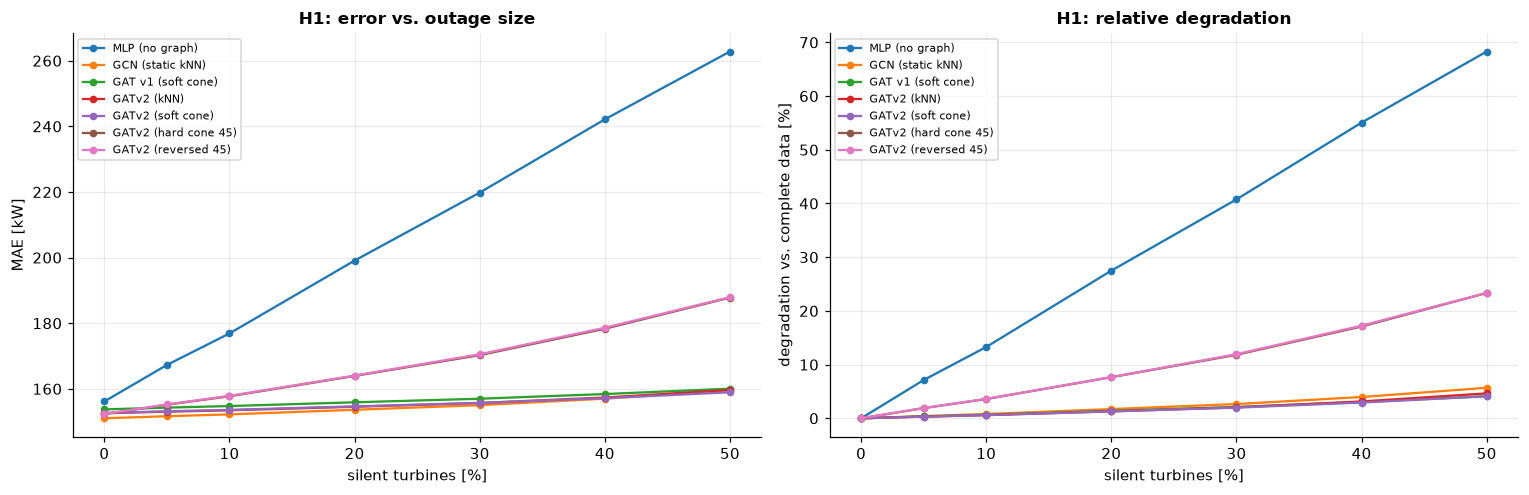

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for name in ZOO:
    sub = summary[(summary.model == name) & summary.scenario.str.startswith("random")].copy()
    if not len(sub):
        continue
    sub["share"] = sub.scenario.str.extract(r"(\d+)%").astype(float) / 100
    sub = sub.sort_values("share")
    xs = [0.0] + list(sub.share)
    base = summary[(summary.model == name) & (summary.scenario == "complete data")]["mean"]
    ys = list(base) + list(sub["mean"])
    axes[0].plot(np.array(xs) * 100, ys, "o-", label=name, ms=4)
    if len(base):
        axes[1].plot(np.array(xs) * 100, (np.array(ys) - base.iloc[0]) / base.iloc[0] * 100,
                     "o-", label=name, ms=4)
axes[0].set(xlabel="silent turbines [%]", ylabel="MAE [kW]", title="H1: error vs. outage size")
axes[1].set(xlabel="silent turbines [%]", ylabel="degradation vs. complete data [%]",
            title="H1: relative degradation")
axes[0].legend(fontsize=7); axes[1].legend(fontsize=7)
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout(); V.save_figure(fig, "stage_e_h1_degradation"); plt.show()

In [19]:
# H1 at each horizon: who loses least?
by_h = results[(results.horizon != "all") & results.scenario.str.startswith("random")]
piv = by_h.groupby(["horizon", "model", "scenario"], observed=True)["MAE"].mean().reset_index()
for h in [f"{hh*10} min" for hh in SPEC.horizons]:
    sub = piv[(piv.horizon == h) & (piv.scenario == "random 30%")].sort_values("MAE")
    print(f"\n--- {h} ahead, 30% of turbines silent ---")
    print(sub[["model", "MAE"]].round(1).to_string(index=False))


--- 10 min ahead, 30% of turbines silent ---
               model   MAE
    GCN (static kNN)  80.7
         GATv2 (kNN)  83.3
   GATv2 (soft cone)  83.6
  GAT v1 (soft cone)  84.4
 GATv2 (reversed 45) 102.9
GATv2 (hard cone 45) 103.0
      MLP (no graph) 159.0

--- 60 min ahead, 30% of turbines silent ---
               model   MAE
   GATv2 (soft cone) 136.1
         GATv2 (kNN) 136.2
    GCN (static kNN) 137.0
  GAT v1 (soft cone) 137.8
GATv2 (hard cone 45) 151.9
 GATv2 (reversed 45) 151.9
      MLP (no graph) 208.1

--- 360 min ahead, 30% of turbines silent ---
               model   MAE
    GCN (static kNN) 247.9
   GATv2 (soft cone) 248.0
         GATv2 (kNN) 248.2
  GAT v1 (soft cone) 249.5
GATv2 (hard cone 45) 256.4
 GATv2 (reversed 45) 257.4
      MLP (no graph) 292.8


## 5. H2 — benefit by number of upwind neighbours

The grouping variable is the **in-degree of the hard 45° cone at the wind direction of that
window** — i.e. how many turbines are actually upwind of this one right now. Stage B showed that
front-row status is direction-dependent, so the grouping is per (window, turbine), not a fixed
turbine list.

A direction-aware model should show a *larger* advantage over the direction-blind baselines in
the high-in-degree groups, and no advantage at in-degree 0.

In [20]:
hard = GraphProvider(fd.loc, fd.farm_dir, fd.t_index, ALPHA, RADIUS, cone_deg=45.0)
groups = E.groups_from_in_degree(preds_by_model[list(ZOO)[0]]["random 30%"], hard)
print(f"in-degree: mean {groups.mean():.2f}, share with 0 upwind neighbours {(groups==0).mean():.1%}")

h2_rows = []
for name, suite in preds_by_model.items():
    pr = suite["random 30%"]
    g = E.group_metrics(pr, groups)
    g["model"] = name
    h2_rows.append(g)
h2 = pd.concat(h2_rows, ignore_index=True)
h2.to_csv(C.TABLES_DIR / "stage_e_h2_by_indegree.csv", index=False)
display(h2.pivot(index="group", columns="model", values="MAE").round(1))

in-degree: mean 2.33, share with 0 upwind neighbours 19.0%


model,GAT v1 (soft cone),GATv2 (hard cone 45),GATv2 (kNN),GATv2 (reversed 45),GATv2 (soft cone),GCN (static kNN),MLP (no graph)
group,,,,,,,
0,164.9,217.7,160.9,160.4,161.6,158.4,215.0
1,172.2,180.7,169.1,176.4,169.7,165.6,229.4
2,168.2,165.8,165.6,175.6,165.8,162.2,220.6
>=3,161.2,157.4,157.3,173.9,158.1,154.7,213.7


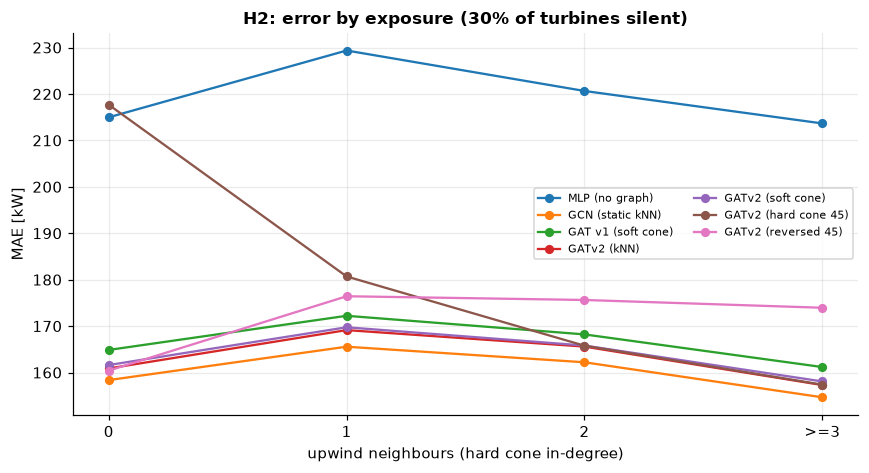

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for name in ZOO:
    sub = h2[h2.model == name]
    ax.plot(sub.group, sub.MAE, "o-", label=name, ms=5)
ax.set(xlabel="upwind neighbours (hard cone in-degree)", ylabel="MAE [kW]",
       title="H2: error by exposure (30% of turbines silent)")
ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.25)
fig.tight_layout(); V.save_figure(fig, "stage_e_h2_exposure"); plt.show()

## 6. H3 — the directional asymmetry

For a directed pair `i -> j` (i upwind of j) that is well aligned with the wind (`along > 0.9`),
two paired conditions are run **on the same windows**:

* **A**: hide `i`, score the error at `j` (the downwind partner);
* **B**: hide `j`, score the error at `i` (the upwind partner).

H3 predicts `A > B`, i.e. a positive mean delta. The Wilcoxon signed-rank test is used.

**Read the result against two controls, otherwise it proves nothing.**

* `MLP (no graph)` **must** give a delta of ≈0: it cannot see its neighbours at all, so hiding
  one cannot change the other's forecast. Any non-zero value there is a bug in the experiment.
* For **`GATv2 (hard cone 45)`** the asymmetry is partly *structural*: the graph only has
  upwind→downwind edges, so there is no path from the downwind turbine to its upwind partner and
  condition B cannot move the upwind prediction by construction. The informative cases are the
  **soft cone** and the **kNN graph**, where edges exist in *both* directions and attention —
  not the topology — decides the asymmetry.

Because this needs the *same* windows for both conditions, the samples are constructed
explicitly: one row per (pair, window), with the hidden set being one endpoint.

In [22]:
def aligned_pairs(t_end, provider, min_along=0.90, max_pairs=200, seed=0):
    """Directed, well-aligned pairs `(i -> j)` at one timestamp (0-based indices)."""
    attrs, mask = provider.edge_attr_for(np.array([t_end]))
    ok = mask[0] & (attrs[0, :, 1] > min_along) & (~provider._is_self)
    idx = np.flatnonzero(ok)
    rng = np.random.default_rng(seed)
    if len(idx) > max_pairs:
        idx = rng.choice(idx, max_pairs, replace=False)
    return provider.src[idx], provider.dst[idx]

def pair_condition(provider, timesteps, horizons, hide_ids, score_ids):
    """Dataset + predictions for 'hide `hide_ids[k]`, score `score_ids[k]`'."""
    n = len(timesteps)
    masks = np.zeros((n, fd.n_turbines), dtype=bool)
    masks[np.arange(n), np.asarray(hide_ids) - 1] = True
    ds = ForecastWindows(fd, np.asarray(timesteps), np.asarray(horizons), SPEC, fixed_hidden=masks)
    return ds, np.asarray(score_ids) - 1

In [23]:
# build a pool of aligned pairs over a sample of test windows
probe = test_t[::max(len(test_t) // 120, 1)][:120]
rows_pairs = []
for t in probe:
    s, d = aligned_pairs(t, hard, seed=int(t))
    for a, b in zip(s, d):
        rows_pairs.append({"t_end": int(t), "upwind": int(a + 1), "downwind": int(b + 1)})
pairs_df = pd.DataFrame(rows_pairs).drop_duplicates(["upwind", "downwind"])
print(f"{len(pairs_df)} aligned directed pairs over {len(probe)} windows")

# keep the pairs that appear often enough to be worth testing
counts = pairs_df.groupby(["upwind", "downwind"]).size().sort_values(ascending=False)
if len(counts) == 0:
    raise RuntimeError("no aligned pairs found at this stride - run with a smaller test_stride")
PICK = counts.head(40).index
pairs_df = pairs_df.set_index(["upwind", "downwind"]).loc[PICK].reset_index()
print(f"selected {len(PICK)} pairs over {pairs_df.t_end.nunique()} windows")
pairs_df.head()

763 aligned directed pairs over 120 windows
selected 40 pairs over 6 windows


,upwind,downwind,t_end
0,1,25,31910
1,1,26,28760
2,1,27,28760
3,1,47,32435
4,1,69,28235


,model,n_pairs,degradation_hide_upwind_kW,degradation_hide_downwind_kW,mean_delta_kW,median_delta_kW,wilcoxon_stat,p_value,cohens_d
0,MLP (no graph),34,0.000,0.000,0.000,0.000,NaN,NaN,NaN
1,GCN (static kNN),34,0.801,1.105,-0.304,0.000,104.0,0.465,-0.036
2,GAT v1 (soft cone),34,3.995,1.904,2.090,3.538,198.0,0.091,0.205
3,GATv2 (kNN),34,0.578,0.917,-0.339,0.000,140.0,0.094,-0.044
4,GATv2 (soft cone),34,2.343,-1.218,3.561,3.965,146.0,0.009,0.351
5,GATv2 (hard cone 45),34,5.112,-0.000,5.112,5.903,160.0,0.018,0.404
6,GATv2 (reversed 45),34,0.000,-5.418,5.418,3.562,173.0,0.033,0.421


mean_delta_kW > 0 supports H3; the no-graph model must be ~0 (it cannot see neighbours).


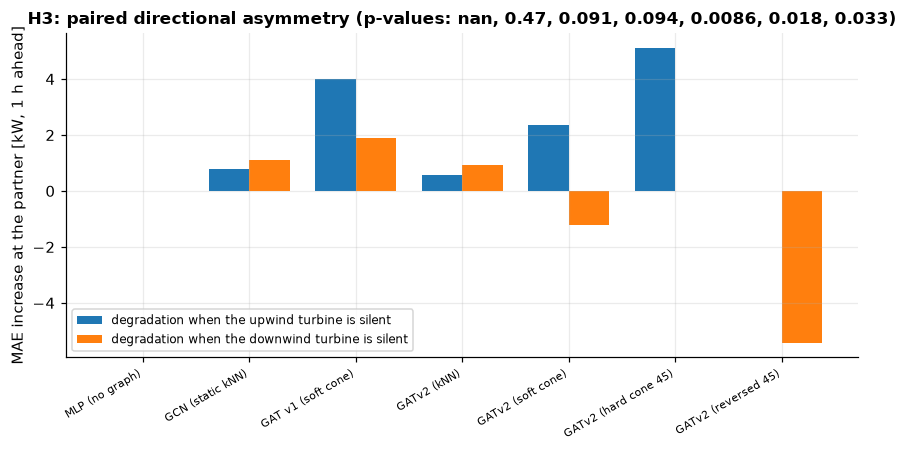

In [24]:
H3_HORIZON = 6      # 1 h ahead: a horizon where graph information should matter
h3_rows = []
for name in ZOO:
    model_i = trained[(name, P["seeds"][0])]
    provider = ZOO[name]["graph"]
    t_pairs = pairs_df.t_end.values
    h_pairs = [H3_HORIZON] * len(pairs_df)
    rows = np.arange(len(pairs_df))

    # baseline: nobody hidden, same windows
    base = TR.predict(model_i, ForecastWindows(fd, t_pairs, h_pairs, SPEC), provider, batch_size=64)
    base_abs = E.error_matrix(base)

    # A: hide the upwind turbine i, score the downwind partner j
    ds_a, partner_a = pair_condition(provider, t_pairs, h_pairs, pairs_df.upwind, pairs_df.downwind)
    pred_a = TR.predict(model_i, ds_a, provider, batch_size=64)
    d_up = E.partner_error(pred_a, partner_a) - base_abs[rows, partner_a]

    # B: hide the downwind turbine j, score the upwind partner i
    ds_b, partner_b = pair_condition(provider, t_pairs, h_pairs, pairs_df.downwind, pairs_df.upwind)
    pred_b = TR.predict(model_i, ds_b, provider, batch_size=64)
    d_down = E.partner_error(pred_b, partner_b) - base_abs[rows, partner_b]

    delta = d_up - d_down
    keep = np.isfinite(delta)
    res = E.paired_direction_test(delta[keep])
    h3_rows.append({"model": name, "n_pairs": int(keep.sum()),
                    "degradation_hide_upwind_kW": float(np.nanmean(d_up[keep])),
                    "degradation_hide_downwind_kW": float(np.nanmean(d_down[keep])),
                    "mean_delta_kW": float(np.nanmean(delta[keep])),
                    "median_delta_kW": float(np.nanmedian(delta[keep])),
                    "wilcoxon_stat": res.stat, "p_value": res.p_value,
                    "cohens_d": res.effect_size})
h3 = pd.DataFrame(h3_rows)
h3.to_csv(C.TABLES_DIR / "stage_e_h3_paired.csv", index=False)
display(h3.round(3))
print("mean_delta_kW > 0 supports H3; the no-graph model must be ~0 (it cannot see neighbours).")
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(h3)); w = 0.38
ax.bar(x - w/2, h3.degradation_hide_upwind_kW, width=w, label="degradation when the upwind turbine is silent")
ax.bar(x + w/2, h3.degradation_hide_downwind_kW, width=w, label="degradation when the downwind turbine is silent")
ax.set_xticks(x); ax.set_xticklabels(h3.model, rotation=30, ha="right", fontsize=7)
ax.set(ylabel="MAE increase at the partner [kW, 1 h ahead]",
       title=f"H3: paired directional asymmetry (p-values: "
             + ", ".join(f"{p:.2g}" for p in h3.p_value) + ")")
ax.legend(fontsize=8); ax.grid(alpha=.25, axis="y")
fig.tight_layout(); V.save_figure(fig, "stage_e_h3_asymmetry"); plt.show()

## 7. Sensitivity: cone angle, radius and orientation

The proposal names noisy wind direction as a risk. The graph is rebuilt for a grid of cone half
angles and radii, keeping everything else fixed. If the conclusions survive a ±15° change in the
cone, the direction estimate is good enough; if they do not, that is the honest answer.

In [25]:
SENS = [("soft cone (180)", dict(cone_deg=180.0)),
        ("hard cone 60",    dict(cone_deg=60.0)),
        ("hard cone 30",    dict(cone_deg=30.0)),
        ("hard cone 15",    dict(cone_deg=15.0)),
        ("R = 1000 m",      dict(cone_deg=45.0, radius_m=1000.0)),
        ("R = 2000 m",      dict(cone_deg=45.0, radius_m=2000.0)),
        ("reversed 45",     dict(cone_deg=45.0, reverse=True))]
if RUN == "smoke":
    SENS = SENS[:2]

base_model = trained[("GATv2 (soft cone)", P["seeds"][0])] if ("GATv2 (soft cone)", P["seeds"][0]) in trained \
    else trained[(list(ZOO)[-1], P["seeds"][0])]
sens_rows = []
for label, kw in SENS:
    kw = {"radius_m": RADIUS, **kw}   # sweep entries may override the radius
    prov = GraphProvider(fd.loc, fd.farm_dir, fd.t_index, alpha_deg=ALPHA, **kw)
    suite = evaluate_suite(base_model, prov)
    # read the table against the degree: at R = 1000 m the cone is so sparse that a low score
    # means "almost no neighbours", not "the direction was wrong"
    ideg = float(prov.in_degree_batch(test_t[::max(len(test_t) // 200, 1)]).mean())
    for scen in ("complete data", "random 30%"):
        sens_rows.append({"variant": label, "mean_in_degree": round(ideg, 2), "scenario": scen,
                          **E.score(suite[scen], label)})
sens = pd.DataFrame(sens_rows)
sens.to_csv(C.TABLES_DIR / "stage_e_sensitivity.csv", index=False)
piv = sens.pivot(index="variant", columns="scenario", values="MAE")
piv.insert(0, "mean_in_degree", sens.groupby("variant", observed=True)["mean_in_degree"].first())
display(piv.round(1))

scenario,mean_in_degree,complete data,random 30%
variant,,,
R = 1000 m,0.4,162.3,209.8
R = 2000 m,3.8,160.1,175.4
hard cone 15,0.8,161.0,190.9
hard cone 30,1.8,160.5,180.5
hard cone 60,2.9,160.1,175.3
reversed 45,2.3,161.4,179.5
soft cone (180),10.9,158.3,160.7


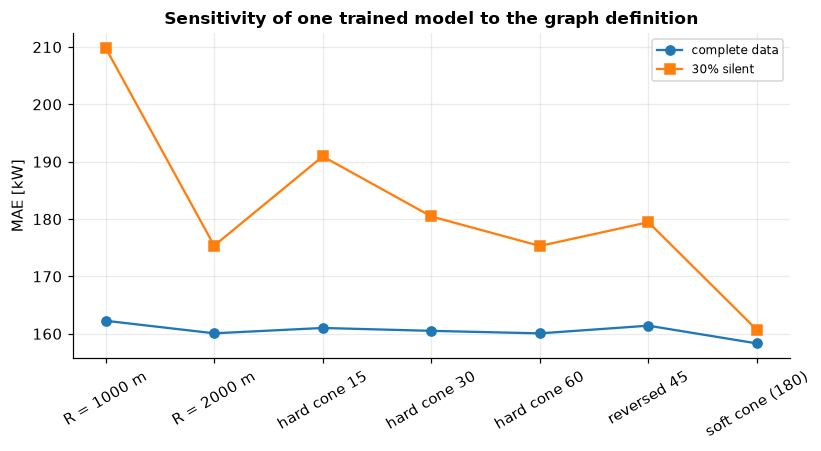

In [26]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
piv = sens.pivot(index="variant", columns="scenario", values="MAE")
ax.plot(piv.index, piv["complete data"], "o-", label="complete data")
ax.plot(piv.index, piv["random 30%"], "s-", label="30% silent")
ax.set(ylabel="MAE [kW]", title="Sensitivity of one trained model to the graph definition")
ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=8); ax.grid(alpha=.25)
fig.tight_layout(); V.save_figure(fig, "stage_e_sensitivity"); plt.show()

## 8. Reading the results

Fill this in from the tables above; the notebook is written so the claims are checkable.

1. **H1.** Compare the curves: does the wind-following model have the flattest degradation, and
   does it beat persistence and the no-graph model at every horizon? Note in particular the
   1-hour and 6-hour horizons — at 10 minutes, persistence is a very hard floor.
2. **H2.** Read the in-degree table row by row: the direction-aware model should gain most in
   the high-in-degree groups. A flat curve would mean the neighbourhood size, not its direction,
   is doing the work.
3. **H3.** The sign of `mean_delta_kW` is the result; the Wilcoxon p-value and Cohen's d say
   whether it is distinguishable from noise. The reversed-orientation control must flip it,
   otherwise the effect is not about direction at all.
4. **Negative results are results.** Stage B already showed the wake signal is buried in shared
   wind variability (deficit ≈ 1.5 ± 1.9 kW), and Stage C showed direction-selectivity hurt value
   recovery. If the same happens in forecasting, the honest conclusion is that on this farm the
   graph helps *because it provides neighbours*, not because it knows which ones are upwind —
   and that conclusion is worth reporting, with the reversed control as evidence.

In [27]:
summary_all = E.seed_summary(results, by=("model", "scenario", "horizon"))
summary_all.to_csv(C.TABLES_DIR / "stage_e_summary.csv", index=False)
print("artifacts saved:")
for p in sorted(C.TABLES_DIR.glob("stage_e_*")):
    print("  ", p.name)

artifacts saved:
   stage_e_h2_by_indegree.csv
   stage_e_h3_paired.csv
   stage_e_results_raw.csv
   stage_e_sensitivity.csv
   stage_e_summary.csv
